Name:Rajat Kumar Majumdar

Roll no. 49

CU240251642

subject : computer vision
# Experiment No. 7: Motion Estimation using Optical Flow Algorithms in Video Sequences

## Objective
To implement, visualize, and compare:
1. **Lucas-Kanade Sparse Optical Flow**
2. **Farneback Dense Optical Flow**

In [14]:
# Step 1 — Import Libraries & Load Video Source
import cv2
import numpy as np
import matplotlib.pyplot as plt

# 0 for webcam or provide a path string like 'sample_video.mp4'
video_source = 0
cap = cv2.VideoCapture(video_source)

ret, first_frame = cap.read()
if not ret:
    raise RuntimeError("Could not open video source. Ensure camera access or valid video file path.")

print("Video stream initialized successfully.")

Video stream initialized successfully.


In [16]:
# Step 2 — Preprocessing & Grayscale Conversion

# Convert the initial frame to grayscale for gradient calculations
prev_gray = cv2.cvtColor(first_frame, cv2.COLOR_BGR2GRAY)

print(f"Frame dimensions: {prev_gray.shape[1]}x{prev_gray.shape[0]}")

Frame dimensions: 640x480


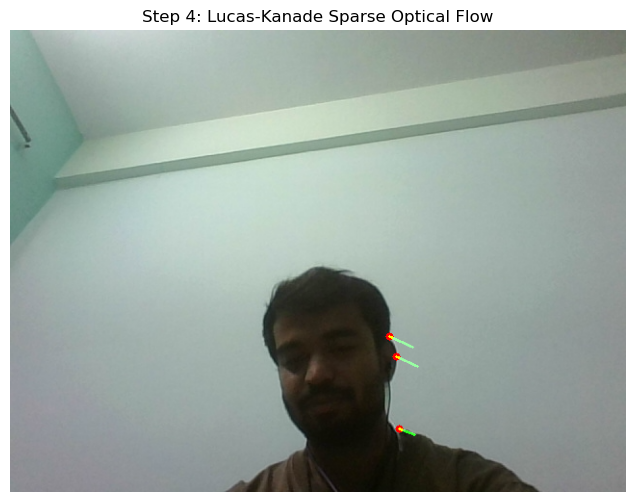

In [18]:
# Step 3 & 4 — Lucas-Kanade Sparse Optical Flow

#Parameters for Shi-Tomasi corner detector (identifying trackable points)
feature_params = dict(
    maxCorners=100,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

# Parameters for Lucas-Kanade optical flow
lk_params = dict(
    winSize=(15, 15),
    maxLevel=2,
    criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 10, 0.03)
)

# Find prominent corners in the first frame
p0 = cv2.goodFeaturesToTrack(prev_gray, mask=None, **feature_params)

# Read the next frame
ret, next_frame = cap.read()
next_gray = cv2.cvtColor(next_frame, cv2.COLOR_BGR2GRAY)

# Calculate sparse optical flow
p1, st, err = cv2.calcOpticalFlowPyrLK(prev_gray, next_gray, p0, None, **lk_params)

# Select valid points
good_new = p1[st == 1]
good_old = p0[st == 1]

# Visualization canvas
sparse_display = next_frame.copy()
trajectory_mask = np.zeros_like(next_frame)

for new, old in zip(good_new, good_old):
    a, b = new.ravel().astype(int)
    c, d = old.ravel().astype(int)
    # Draw green motion line and red point
    trajectory_mask = cv2.line(trajectory_mask, (a, b), (c, d), (0, 255, 0), 2)
    sparse_display = cv2.circle(sparse_display, (a, b), 4, (0, 0, 255), -1)

sparse_output = cv2.add(sparse_display, trajectory_mask)

# Display in notebook
plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(sparse_output, cv2.COLOR_BGR2RGB))
plt.title("Step 4: Lucas-Kanade Sparse Optical Flow")
plt.axis("off")
plt.show()

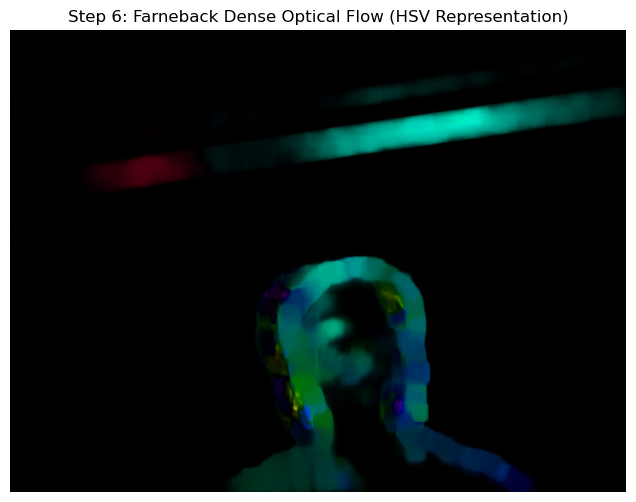

In [20]:
# Step 5 & 6 — Farneback Dense Optical Flow
# Compute dense optical flow for every pixel
flow = cv2.calcOpticalFlowFarneback(
    prev_gray,
    next_gray,
    None,
    pyr_scale=0.5,
    levels=3,
    winsize=15,
    iterations=3,
    poly_n=5,
    poly_sigma=1.2,
    flags=0
)

# Map flow vectors (dx, dy) to polar coordinates (magnitude, angle)
magnitude, angle = cv2.cartToPolar(flow[..., 0], flow[..., 1])

# Build an HSV image representation:
# Hue = Direction, Saturation = 255, Value = Normalized Magnitude
hsv = np.zeros_like(next_frame)
hsv[..., 1] = 255
hsv[..., 0] = angle * 180 / np.pi / 2
hsv[..., 2] = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX)

# Convert to BGR for display
dense_output = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

# Display in notebook
plt.figure(figsize=(8, 6))
plt.imshow(cv2.cvtColor(dense_output, cv2.COLOR_BGR2RGB))
plt.title("Step 6: Farneback Dense Optical Flow (HSV Representation)")
plt.axis("off")
plt.show()

# Release capture resource
cap.release()

### Step 7: Comparison of Lucas-Kanade and Farneback Algorithms

| Parameter | Lucas-Kanade (Sparse) | Farneback (Dense) |
|---|---|---|
| **Coverage** | Only selected feature points (corners) | Every individual pixel across the frame |
| **Mathematical Method** | Local window least-squares fit | Global/local quadratic polynomial expansion |
| **Computational Cost** | Low (real-time, embedded devices) | High (requires heavier CPU/GPU workloads) |
| **Uniform/Flat Regions** | Fails / Skipped (zero gradients) | Interpolates displacement across neighborhoods |
| **Primary Use Cases** | Object tracking, visual odometry | Scene flow, video stabilization, segmentation |

# Step 8 & 9 — Sensitivity & Real-World Application Analysis
### Step 8: Factors Influencing Optical Flow
1. **Object Speed:** Fast motion breaks the small-displacement assumption. Multi-scale Gaussian pyramids are required to handle larger displacements.
2. **Lighting Variations:** Sudden flashes or shadows violate the fundamental brightness constancy assumption:
   $$I(x, y, t) = I(x + \Delta x, y + \Delta y, t + \Delta t)$$
3. **Camera Motion (Ego-motion):** Moving cameras produce full-field global flow, which requires homography estimation or background subtraction to isolate independent moving objects.

### Step 9: Application Suitability
* **Lucas-Kanade:** Ideal for resource-constrained platforms, robotic visual odometry, and marker/target tracking where high framerates matter more than full scene coverage.
* **Farneback:** Ideal for autonomous driving free-space detection, collision risk estimation, and background flow cancellation.

### Step 10: Summary of Observations
* Optical flow estimates apparent pixel velocity based on spatial gradients ($I_x, I_y$) and temporal variations ($I_t$).
* The **aperture problem** makes motion ambiguous along linear edges, which is why sparse methods rely on 2D features like corners.
* Sparse optical flow offers rapid frame rates at the expense of spatial density, while dense optical flow provides complete scene geometry at higher computational overhead.

## Lab Questions and Solutions

### Q1. What is Optical Flow? How is it used in computer vision?
**Answer:**  
Optical flow is the pattern of apparent motion of objects, surfaces, and edges in a visual sequence caused by the relative motion between the camera and the scene.  
In computer vision, it provides 2D instantaneous velocity vectors for pixels, forming the backbone for object tracking, video stabilization, visual odometry, action recognition, and collision estimation.

---

### Q2. Explain the working principle of the Lucas-Kanade Optical Flow algorithm.
**Answer:**  
Lucas-Kanade assumes the velocity vector $(u, v)$ is constant within a small $n \times n$ neighborhood $\Omega$ around a target pixel. Using the optical flow constraint:
$$I_x u + I_y v + I_t = 0$$

An overdetermined system of $N = n^2$ equations is formed:
$$A v = b$$

Where:
$$
A = \begin{bmatrix} I_x(p_1) & I_y(p_1) \\ \vdots & \vdots \\ I_x(p_N) & I_y(p_N) \end{bmatrix}, \quad
v = \begin{bmatrix} u \\ v \end{bmatrix}, \quad
b = -\begin{bmatrix} I_t(p_1) \\ \vdots \\ I_t(p_N) \end{bmatrix}
$$

The solution is computed via the least-squares formula:
$$v = (A^T A)^{-1} A^T b$$
The matrix $A^T A$ is invertible when both eigenvalues are sufficiently large, making corners (e.g., Shi-Tomasi) ideal points.

---

### Q3. What is Dense Optical Flow? How does it differ from Sparse Optical Flow?
**Answer:**  
* **Sparse Optical Flow:** Evaluates displacement vectors only at selected interest points (e.g., corners or edges).
* **Dense Optical Flow:** Computes displacement vectors for **every single pixel** in the frame, creating a full-field motion representation.

---

### Q4. Compare the Lucas-Kanade and Farneback optical flow algorithms.
**Answer:**  
* **Coverage:** Lucas-Kanade tracks sparse points; Farneback tracks all pixels.
* **Mechanism:** Lucas-Kanade uses local least-squares; Farneback approximates neighborhoods with quadratic polynomials.
* **Speed:** Lucas-Kanade is lightweight and fast; Farneback is computationally heavy.
* **Texture Dependency:** Lucas-Kanade fails in uniform regions; Farneback estimates motion even across smooth regions using neighborhood context.

---

### Q5. What assumptions are made while computing optical flow?
**Answer:**  
1. **Brightness Constancy:** Pixel intensity remains constant across consecutive frames along the motion trajectory ($I(x, y, t) = I(x + \Delta x, y + \Delta y, t + \Delta t)$).
2. **Small Displacements:** Motion between consecutive frames is small enough for first-order Taylor expansion approximations to hold.
3. **Spatial Coherence:** Neighboring pixels belong to the same physical surface and have similar velocity.

---

### Q6. What factors can affect the accuracy of optical flow estimation?
**Answer:**  
* **The Aperture Problem:** Uniform edges only reveal motion perpendicular to the edge direction.
* **Illumination Changes:** Sudden changes in ambient light or dynamic shadows violate brightness constancy.
* **Large Motions:** Displacements exceeding the algorithm's window size cause tracking failure unless addressed with Gaussian pyramids.
* **Occlusions:** Points entering or exiting behind objects lack valid correspondences.
* **Reflective Surfaces:** Specular highlights move independently of the underlying surface geometry.

---

### Q7. Mention five real-world applications of optical flow in computer vision.
**Answer:**  
1. **Autonomous Vehicles:** Focus of expansion (FOE) analysis and Time-to-Collision (TTC) calculation.
2. **Video Stabilization:** Compensating for camera shake and high-frequency vibrations.
3. **Automated Video Surveillance:** Detecting intruder motion and abnormal trajectory behaviors.
4. **Action & Gesture Recognition:** Supplying motion features to deep learning classifiers.
5. **Drone Navigation (MAVs):** Ground-relative velocity estimation in GPS-denied environments.

---

### Q8. Why are grayscale images generally used for optical flow computation?
**Answer:**  
1. **Computational Efficiency:** Reduces 3-channel (RGB) images to a single intensity matrix, cutting memory and processing overhead by approximately two-thirds.
2. **Sufficient Gradient Data:** Differential optical flow relies directly on luminance derivatives ($I_x, I_y, I_t$); color chromaticity rarely provides additional geometric displacement accuracy.

---

### Q9. What are the limitations of optical flow algorithms in real-world environments?
**Answer:**  
* High vulnerability to motion blur caused by slow shutter speeds or rapid camera rotation.
* Inability to differentiate actual geometric motion from apparent motion (e.g., cast shadows moving across flat ground).
* Substantial memory and computational overhead for high-resolution dense flow on embedded systems.
* Difficulty modeling non-rigid deformations and discontinuous motion boundaries.

---

### Q10. How does optical flow contribute to applications such as autonomous driving, video surveillance, and action recognition?
**Answer:**  
* **Autonomous Driving:** Delivers real-time relative motion and field divergence to detect cut-in vehicles and calculate braking time without requiring prior semantic classification.
* **Video Surveillance:** Enables robust background separation, isolating foreground moving objects even in dynamic environments (e.g., moving escalators, swaying branches).
* **Action Recognition:** Encodes explicit kinematic vectors into two-stream convolutional networks, allowing models to learn temporal dynamics independent of background scenery or actor appearance.